## What are the most demanded skills for the top 3 most popular data roles?

### Methodology
- Clean-up skill column
- Calculate skill count based on 'job_title_short'
- Calculate skill percentage
- Plot final findings

In [1]:
import ast 
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()


# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df['job_skills']

0                                                       NaN
1                [r, python, sql, nosql, power bi, tableau]
2         [python, sql, c#, azure, airflow, dax, docker,...
3         [python, c++, java, matlab, aws, tensorflow, k...
4         [bash, python, oracle, aws, ansible, puppet, j...
                                ...                        
785736    [bash, python, perl, linux, unix, kubernetes, ...
785737                               [sas, sas, sql, excel]
785738                                  [powerpoint, excel]
785739    [python, go, nosql, sql, mongo, shell, mysql, ...
785740                                          [aws, flow]
Name: job_skills, Length: 785741, dtype: object

In [3]:
top_roles = ['Data Analyst', 'Data Scientist', 'Data Engineer']

df_top3 = df.loc[
    (df['job_title_short'].isin(top_roles)) &
    (df['job_country'] == 'United States')
].copy()

df_top3 = df_top3.explode('job_skills')

In [4]:
skill_counts = (
    df_top3.groupby(['job_title_short', 'job_skills'])
    .size()
    .reset_index(name='skill_count')
)

top5_skills = (
    skill_counts.sort_values(['job_title_short', 'skill_count'], ascending=[True, False])
    .groupby('job_title_short')
    .head(5)
)

top5_skills

,job_title_short,job_skills,skill_count
175,Data Analyst,sql,34452
54,Data Analyst,excel,27519
186,Data Analyst,tableau,19311
141,Data Analyst,python,18382
156,Data Analyst,sas,13200
397,Data Engineer,sql,23958
362,Data Engineer,python,22762
233,Data Engineer,aws,15018
234,Data Engineer,azure,11321
392,Data Engineer,spark,11242


In [10]:
postings = df_top3.reset_index(names='posting_id')

total_jobs_by_role = postings.groupby('job_title_short')['posting_id'].nunique()

skill_job_counts = (
    postings.dropna(subset=['job_skills'])
    .drop_duplicates(['posting_id', 'job_skills'])
    .groupby(['job_title_short', 'job_skills'])['posting_id']
    .nunique()
    .rename('jobs_with_skill')
    .reset_index()
)

top5_job_percentages = top5_skills.merge(
    skill_job_counts,
    on=['job_title_short', 'job_skills'],
    how='left'
)

top5_job_percentages['total_jobs'] = (
    top5_job_percentages['job_title_short'].map(total_jobs_by_role)
)
top5_job_percentages['job_percent'] = (
    top5_job_percentages['jobs_with_skill']
    / top5_job_percentages['total_jobs'] * 100
)

top5_job_percentages.sort_values(
    ['job_title_short', 'job_percent'], ascending=[True, False]
)

,job_title_short,job_skills,skill_count,jobs_with_skill,total_jobs,job_percent
0,Data Analyst,sql,34452,34452,67816,50.802171
1,Data Analyst,excel,27519,27519,67816,40.578919
2,Data Analyst,tableau,19311,19311,67816,28.475581
3,Data Analyst,python,18382,18382,67816,27.105698
4,Data Analyst,sas,13200,6600,67816,9.732217
5,Data Engineer,sql,23958,23958,35080,68.295325
6,Data Engineer,python,22762,22762,35080,64.885975
7,Data Engineer,aws,15018,15018,35080,42.810718
8,Data Engineer,azure,11321,11321,35080,32.271950
9,Data Engineer,spark,11242,11242,35080,32.046750


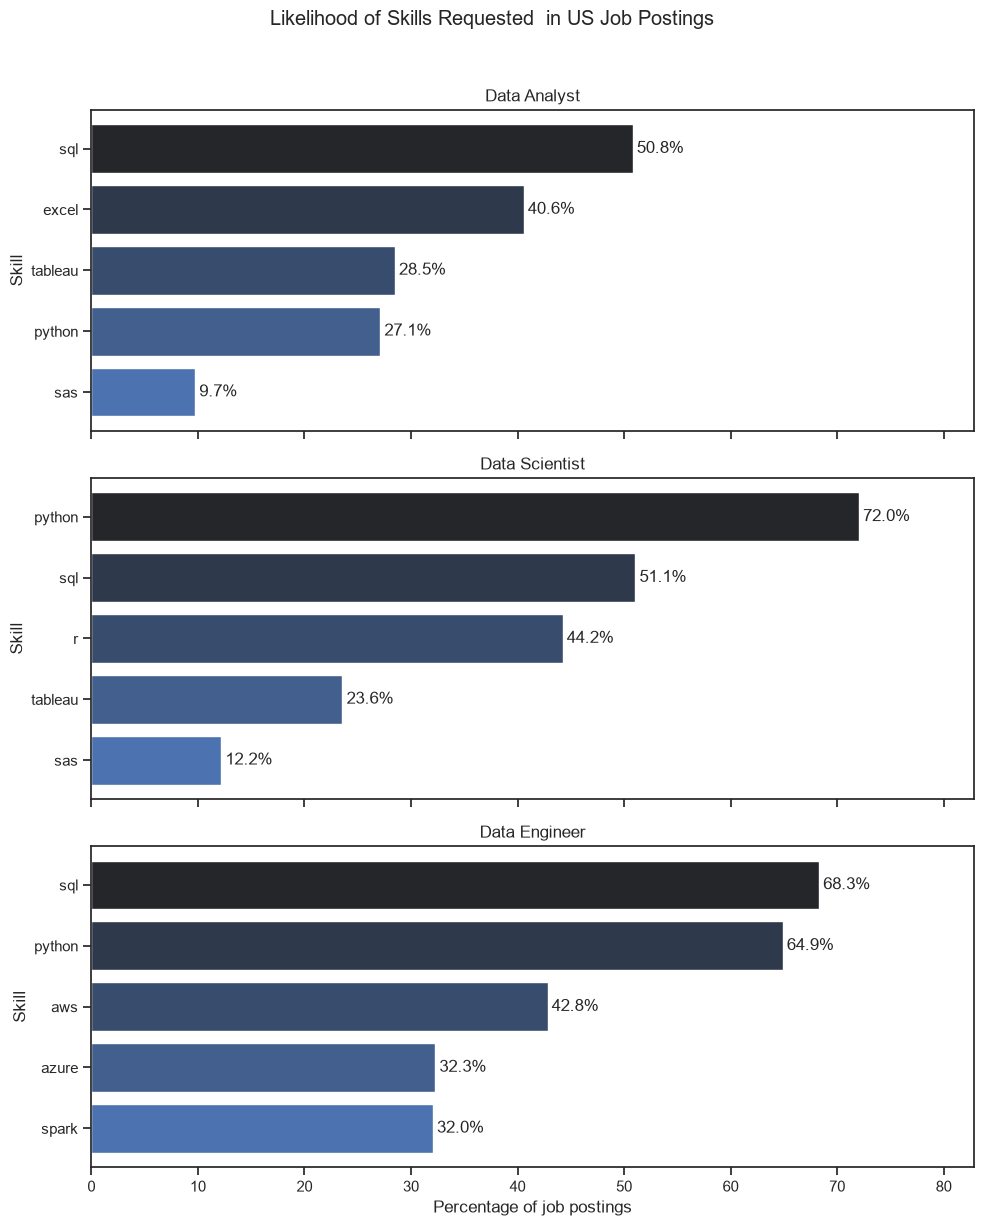

In [17]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 12), sharex=True)

sns.set_theme(style = 'ticks')
palette = sns.color_palette("dark:b_r", n_colors=5)


x_limit = top5_job_percentages["job_percent"].max() * 1.15

for ax, role in zip(axes, top_roles):
    role_data = (
        top5_job_percentages[top5_job_percentages["job_title_short"] == role]
        .sort_values("job_percent", ascending=True)
    )

    bars = ax.barh(
        role_data["job_skills"],
        role_data["job_percent"],
        color=palette[:len(role_data)]
    )
    ax.set_title(role)
    ax.set_xlim(0, x_limit)
    ax.set_ylabel("Skill")
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

axes[-1].set_xlabel("Percentage of job postings")
fig.suptitle("Likelihood of Skills Requested  in US Job Postings", y=1.02)
fig.tight_layout()
plt.show()